## 1. Imports and Config

In [1]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    cross_val_predict, learning_curve
)
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings('ignore')

artifacts = joblib.load('eda_artifacts.pkl')
df = artifacts['df']
num_features = artifacts['num_features']
iso_anomaly  = artifacts['iso_anomaly']

print('Data loaded from EDA.')

Data loaded from EDA.


---
## 2. Data Preparation

In [ ]:
df_model = df[num_features + ['Type', 'Target']].copy()


df_model['iso_score'] = iso_anomaly

df_model = pd.get_dummies(df_model, columns=['Type'], drop_first=False)

feature_cols = [c for c in df_model.columns if c != 'Target']
X_all = df_model[feature_cols].values
y_all = df_model['Target'].values

X_train_calib, X_test, y_train_calib, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=17, stratify=y_all
)
X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_calib, y_train_calib, test_size=0.176, random_state=17, stratify=y_train_calib
)
# 0.176 * 0.85 ≈ 0.15  ->  train≈70%, calib≈15%, test≈15%

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_calib_sc = scaler.transform(X_calib)
X_test_sc = scaler.transform(X_test)
X_train_calib_sc = scaler.transform(X_train_calib)

classes = np.unique(y_train)
cw = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, cw))

print(f'Train: {X_train.shape[0]} samples')
print(f'Calib: {X_calib.shape[0]} samples')
print(f'Test:  {X_test.shape[0]} samples')
print(f'Train failures: {y_train.sum()} ({y_train.mean()*100:.1f}%)')
print(f'Calib failures: {y_calib.sum()} ({y_calib.mean()*100:.1f}%)')
print(f'Test  failures: {y_test.sum()}  ({y_test.mean()*100:.1f}%)')
print(f'\nClass weights: {class_weight_dict}')
print(f'\nFeatures ({len(feature_cols)}): {feature_cols}')

Train: 7004 samples
Calib: 1496 samples
Test:  1500 samples
Train failures: 237 (3.4%)
Calib failures: 51 (3.4%)
Test  failures: 51  (3.4%)

Class weights: {np.int64(0): np.float64(0.5175114526378011), np.int64(1): np.float64(14.776371308016877)}

Features (9): ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'iso_score', 'Type_H', 'Type_L', 'Type_M']


---
## 3. Hyperparameter Tuning - Architecture Search

Best architecture:    (64, 32)
Best alpha (L2):      0.01
Best learning_rate:   0.001
Best CV ROC-AUC:      0.9505


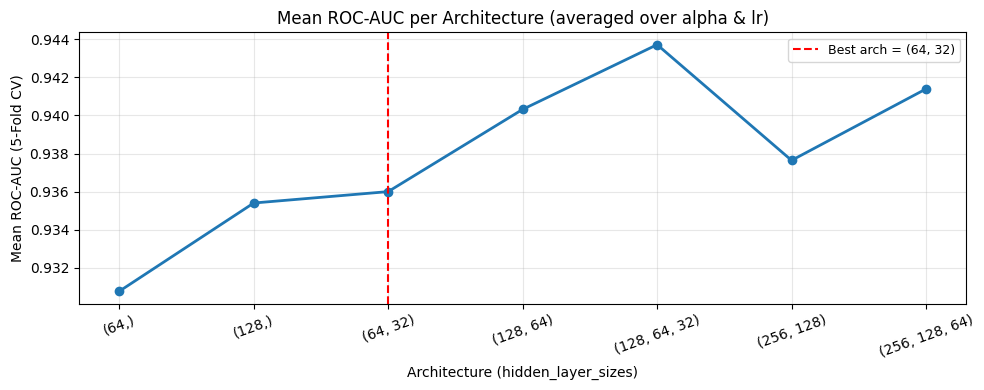

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

architectures = [
    (64,),
    (128,),
    (64, 32),
    (128, 64),
    (128, 64, 32),
    (256, 128),
    (256, 128, 64),
]
alphas          = [1e-4, 1e-3, 1e-2]
learning_rates  = [1e-3, 3e-4]

best_score = -np.inf
best_params = {}
results_grid = []

for arch in architectures:
    for alpha in alphas:
        for lr in learning_rates:
            mlp_pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('mlp', MLPClassifier(
                    hidden_layer_sizes=arch,
                    activation='relu',
                    solver='adam',
                    alpha=alpha,
                    learning_rate_init=lr,
                    max_iter=300,
                    random_state=17,
                    early_stopping=True,
                    validation_fraction=0.1,
                    n_iter_no_change=15
                ))
            ])
            sample_weight_train = np.where(y_train == 1, class_weight_dict[1], class_weight_dict[0])
            fold_scores = []

            for train_idx, valid_idx in cv.split(X_train, y_train):
                X_tr, X_val = X_train[train_idx], X_train[valid_idx]
                y_tr, y_val = y_train[train_idx], y_train[valid_idx]
                sw_tr = sample_weight_train[train_idx]

                mlp_pipe.fit(X_tr, y_tr, mlp__sample_weight=sw_tr)
                y_val_proba = mlp_pipe.predict_proba(X_val)[:, 1]
                fold_scores.append(roc_auc_score(y_val, y_val_proba))

            cv_res = {'test_score': np.array(fold_scores)}
            score = cv_res['test_score'].mean()
            results_grid.append((arch, alpha, lr, score))
            if score > best_score:
                best_score  = score
                best_params = {'arch': arch, 'alpha': alpha, 'lr': lr}

best_arch = best_params['arch']
best_alpha = best_params['alpha']
best_lr    = best_params['lr']

print(f'Best architecture:    {best_arch}')
print(f'Best alpha (L2):      {best_alpha}')
print(f'Best learning_rate:   {best_lr}')
print(f'Best CV ROC-AUC:      {best_score:.4f}')

arch_scores = {}
for arch, alpha, lr, score in results_grid:
    arch_scores.setdefault(str(arch), []).append(score)
arch_means  = [np.mean(v) for v in arch_scores.values()]
arch_labels = list(arch_scores.keys())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(arch_labels, arch_means, marker='o', lw=2)
ax.axvline(
    arch_labels.index(str(best_arch)),
    color='red', linestyle='--', lw=1.5,
    label=f'Best arch = {best_arch}'
)
ax.set_title('Mean ROC-AUC per Architecture (averaged over alpha & lr)')
ax.set_xlabel('Architecture (hidden_layer_sizes)')
ax.set_ylabel('Mean ROC-AUC (5-Fold CV)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

---
## 4. Training and Basic Evaluation

In [5]:
sample_weight_train = np.where(y_train == 1, class_weight_dict[1], class_weight_dict[0])

mlp = MLPClassifier(
    hidden_layer_sizes=best_arch,
    activation='relu',
    solver='adam',
    alpha=best_alpha,
    learning_rate_init=best_lr,
    max_iter=500,
    random_state=17,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20
)
mlp.fit(X_train_sc, y_train, sample_weight=sample_weight_train)

y_pred  = mlp.predict(X_test_sc)
y_proba = mlp.predict_proba(X_test_sc)[:, 1]

print('- Classification Report -')
print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))

roc_auc  = roc_auc_score(y_test, y_proba)
avg_prec = average_precision_score(y_test, y_proba)
print(f'ROC-AUC: {roc_auc:.4f}')
print(f'Average Precision: {avg_prec:.4f}')
print(f'\nIterations run: {mlp.n_iter_}')
print(f'Best validation score: {mlp.best_validation_score_:.4f}')

- Classification Report -
              precision    recall  f1-score   support

  No Failure       1.00      0.94      0.97      1449
     Failure       0.36      0.92      0.52        51

    accuracy                           0.94      1500
   macro avg       0.68      0.93      0.74      1500
weighted avg       0.98      0.94      0.95      1500

ROC-AUC: 0.9799
Average Precision: 0.7909

Iterations run: 103
Best validation score: 0.9626


---
## 5. Confusion Matrix

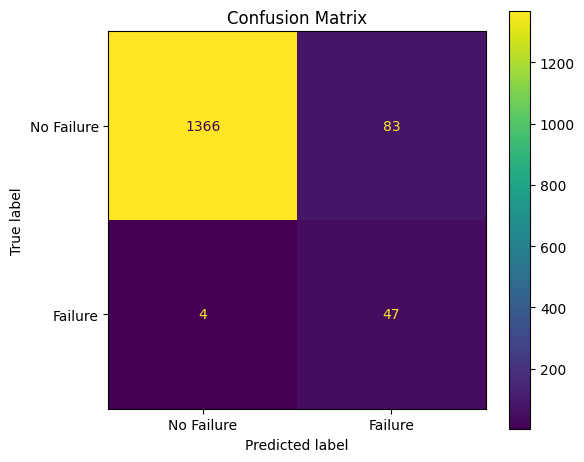


False Alarm Rate: 0.057
Miss Rate: 0.078


In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Failure', 'Failure'])
disp.plot(ax=ax)
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'\nFalse Alarm Rate: {fp/(fp+tn):.3f}')
print(f'Miss Rate: {fn/(fn+tp):.3f}')

---
## 6. ROC Curve and Precision-Recall Curve

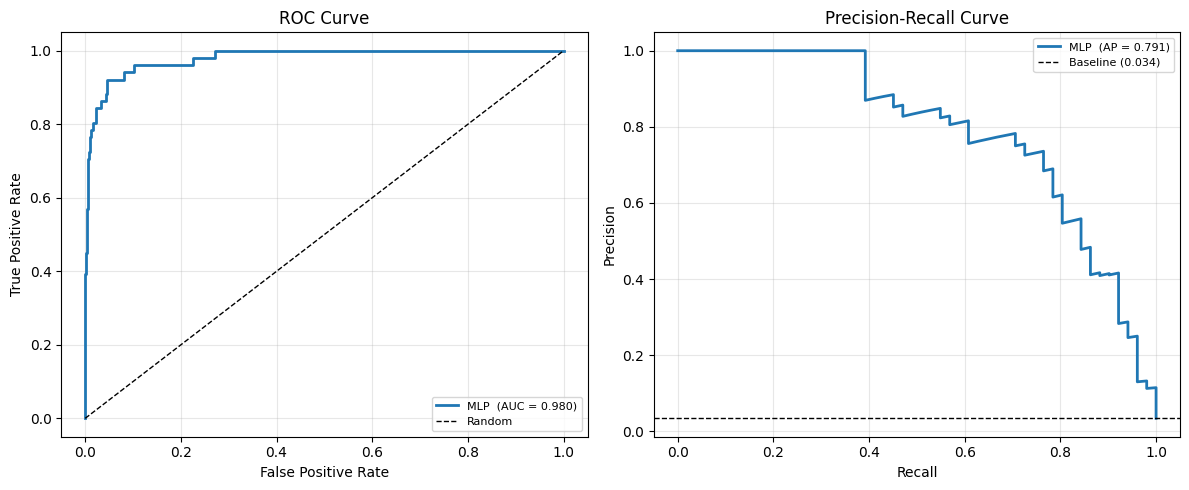

In [7]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
ax = axes[0]
ax.plot(fpr, tpr, lw=2, label=f'MLP  (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Precision-Recall
ax = axes[1]
ax.plot(rec, prec, lw=2, label=f'MLP  (AP = {avg_prec:.3f})')
baseline = y_test.mean()
ax.axhline(baseline, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 7. Loss Curve

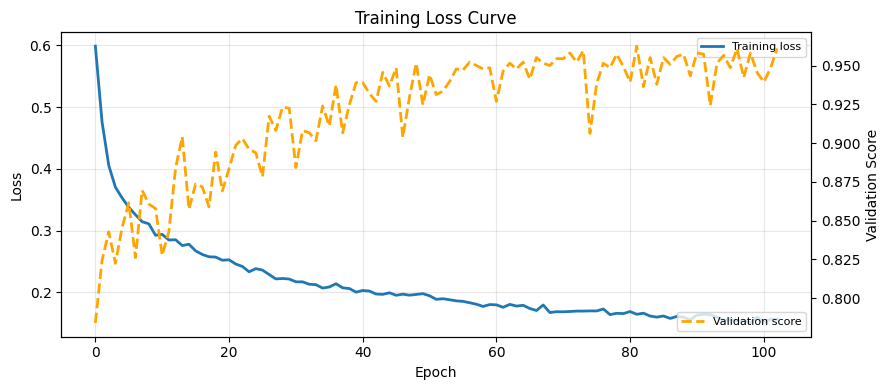

Training converged after 103 epochs (early stopping active)


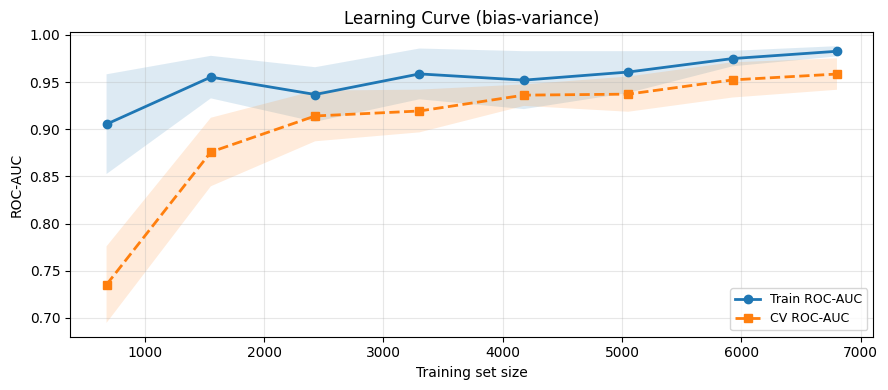

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mlp.loss_curve_, lw=2, label='Training loss')
if hasattr(mlp, 'validation_scores_') and mlp.validation_scores_ is not None:
    ax2 = ax.twinx()
    ax2.plot(
        mlp.validation_scores_, lw=2,
        color='orange', linestyle='--', label='Validation score'
    )
    ax2.set_ylabel('Validation Score')
    ax2.legend(loc='lower right', fontsize=8)
ax.set_title('Training Loss Curve')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.legend(loc='upper right', fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Training converged after {mlp.n_iter_} epochs (early stopping active)')

lc_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=best_arch,
        activation='relu',
        solver='adam',
        alpha=best_alpha,
        learning_rate_init=best_lr,
        max_iter=500,
        random_state=17,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20
    ))
])

train_sizes, train_scores, val_scores = learning_curve(
    lc_pipeline, X_train_calib, y_train_calib,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=17),
    scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1,
    fit_params={'mlp__sample_weight':
        np.where(y_train_calib == 1, class_weight_dict[1], class_weight_dict[0])}
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(train_sizes, train_scores.mean(axis=1), 'o-', lw=2, label='Train ROC-AUC')
ax.fill_between(train_sizes,
                train_scores.mean(axis=1) - train_scores.std(axis=1),
                train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.15)
ax.plot(train_sizes, val_scores.mean(axis=1), 's--', lw=2, label='CV ROC-AUC')
ax.fill_between(train_sizes,
                val_scores.mean(axis=1) - val_scores.std(axis=1),
                val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.15)
ax.set_title('Learning Curve (bias-variance)')
ax.set_xlabel('Training set size')
ax.set_ylabel('ROC-AUC')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 8. Cross-validation (Stratified 5-Fold)

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

mlp_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=best_arch,
        activation='relu',
        solver='adam',
        alpha=best_alpha,
        learning_rate_init=best_lr,
        max_iter=500,
        random_state=17,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20
    ))
])

sample_weight_tc = np.where(y_train_calib == 1, class_weight_dict[1], class_weight_dict[0])

cv_results = cross_validate(
    mlp_pipeline, X_train_calib, y_train_calib, cv=cv,
    scoring=['roc_auc', 'average_precision', 'f1', 'recall', 'precision'],
    return_train_score=False,
    params={'mlp__sample_weight': sample_weight_tc}
)

metrics = {
    'ROC-AUC': cv_results['test_roc_auc'],
    'Avg Precision': cv_results['test_average_precision'],
    'F1 (Failure)': cv_results['test_f1'],
    'Recall (Failure)': cv_results['test_recall'],
    'Precision (Failure)': cv_results['test_precision'],
}

print('- Cross-Validation Results (5-Fold on train+calib set) -')
print(f'{"Metric":<23} {"Mean":>8} {"Std":>8} {"Min":>8} {"Max":>8}')
print('-' * 60)
for name, vals in metrics.items():
    print(f'{name:<25} {vals.mean():>8.4f} {vals.std():>8.4f} {vals.min():>8.4f} {vals.max():>8.4f}')

- Cross-Validation Results (5-Fold on train+calib set) -
Metric                      Mean      Std      Min      Max
------------------------------------------------------------
ROC-AUC                     0.9585   0.0167   0.9313   0.9826
Avg Precision               0.6606   0.0622   0.5733   0.7212
F1 (Failure)                0.4225   0.0680   0.3446   0.5241
Recall (Failure)            0.8546   0.0774   0.7586   0.9825
Precision (Failure)         0.2856   0.0642   0.2143   0.3769
